In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Model parameters
n = 101
D = 1.0
c0 = 0.2
k = 1.0

# Price parameters
p_max = 10.0
dp = 0.1

# Possible locations
road = np.linspace(-1, 1, n)

# Possible prices
prices = np.arange(0, p_max + dp/2, dp)

# Demand per customer
demand_per_customer = D / n

print("Number of locations:", len(road))
print("Number of prices:", len(prices))

Number of locations: 101
Number of prices: 101


In [3]:
action_matrix = np.array([
    [x, p]
    for x in road
    for p in prices
])

print("Action matrix shape:", action_matrix.shape)

Action matrix shape: (10201, 2)


In [4]:
def calculate_profit(x1, x2, p1, p2):

    # Total cost for every customer
    cost1 = p1 + k * np.abs(road - x1)
    cost2 = p2 + k * np.abs(road - x2)

    # Customers choose the cheapest firm
    customers1 = np.sum(cost1 < cost2)
    customers2 = np.sum(cost2 < cost1)

    # Split customers equally if total cost is the same
    ties = np.sum(np.isclose(cost1, cost2))

    customers1 += 0.5 * ties
    customers2 += 0.5 * ties

    # Quantity sold
    Q1 = customers1 * demand_per_customer
    Q2 = customers2 * demand_per_customer

    # Profit
    profit1 = (p1 - c0) * Q1
    profit2 = (p2 - c0) * Q2

    return profit1, profit2

In [5]:
def global_best_move(x1, x2, p1, p2, firm):

    best_profit = -np.inf
    best_x = None
    best_p = None

    # Search through ALL combinations
    for x, p in action_matrix:

        if firm == 1:
            profit = calculate_profit(x, x2, p, p2)[0]

        else:
            profit = calculate_profit(x1, x, p1, p)[1]

        if profit > best_profit:
            best_profit = profit
            best_x = x
            best_p = p

    return best_x, best_p

In [6]:
# Random starting positions
x1, x2 = np.random.choice(road, 2)

# Random starting prices
p1, p2 = np.random.choice(prices, 2)

print(f"Starting Firm 1: x={x1:.2f}, p={p1:.2f}")
print(f"Starting Firm 2: x={x2:.2f}, p={p2:.2f}")

Starting Firm 1: x=-0.68, p=9.00
Starting Firm 2: x=0.00, p=3.80


In [7]:
# Save starting values
history_x1 = [x1]
history_x2 = [x2]

history_p1 = [p1]
history_p2 = [p2]


# Dictionary for detecting cycles
seen_states = {}

max_iterations = 1000


for iteration in range(max_iterations):

    # Current state
    state = (
        round(x1, 6),
        round(x2, 6),
        round(p1, 6),
        round(p2, 6)
    )

    # Check for cycle
    if state in seen_states:

        first_iteration = seen_states[state]
        cycle_length = iteration - first_iteration

        print("Cycle detected!")
        print(f"First seen at iteration: {first_iteration}")
        print(f"Repeated at iteration: {iteration}")
        print(f"Cycle length: {cycle_length}")
        print(f"Repeated state: {state}")

        break

    seen_states[state] = iteration


    # Save current values
    old_x1, old_x2 = x1, x2
    old_p1, old_p2 = p1, p2


    # Both firms calculate their global best response
    # using the OLD state
    new_x1, new_p1 = global_best_move(
        old_x1, old_x2,
        old_p1, old_p2,
        1
    )

    new_x2, new_p2 = global_best_move(
        old_x1, old_x2,
        old_p1, old_p2,
        2
    )


    # Update both firms
    x1, p1 = new_x1, new_p1
    x2, p2 = new_x2, new_p2


    # Save history
    history_x1.append(x1)
    history_x2.append(x2)

    history_p1.append(p1)
    history_p2.append(p2)


    # Check for convergence
    if np.allclose(
        [x1, x2, p1, p2],
        [old_x1, old_x2, old_p1, old_p2]
    ):

        print(f"Converged after {iteration + 1} iterations")
        break

else:
    print(f"No convergence or cycle after {max_iterations} iterations")

Cycle detected!
First seen at iteration: 331
Repeated at iteration: 351
Cycle length: 20
Repeated state: (np.float64(-0.3), np.float64(0.14), np.float64(0.9), np.float64(1.0))


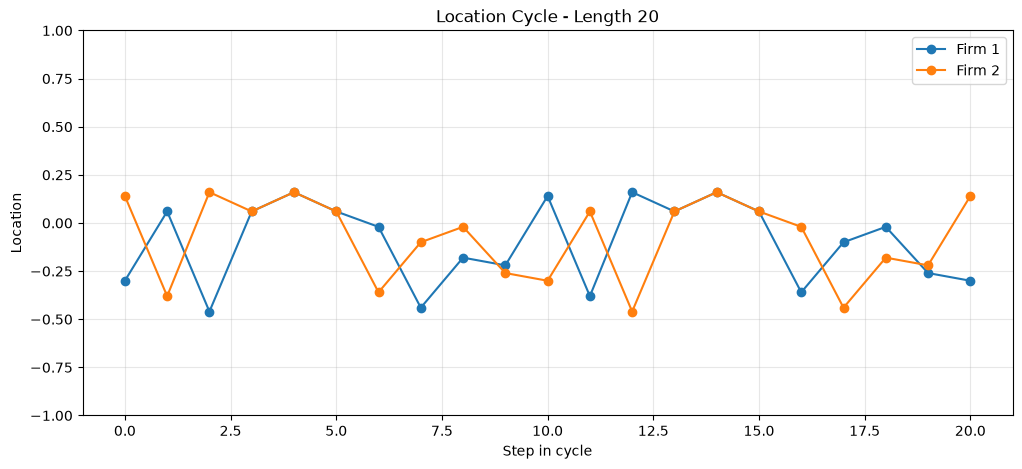

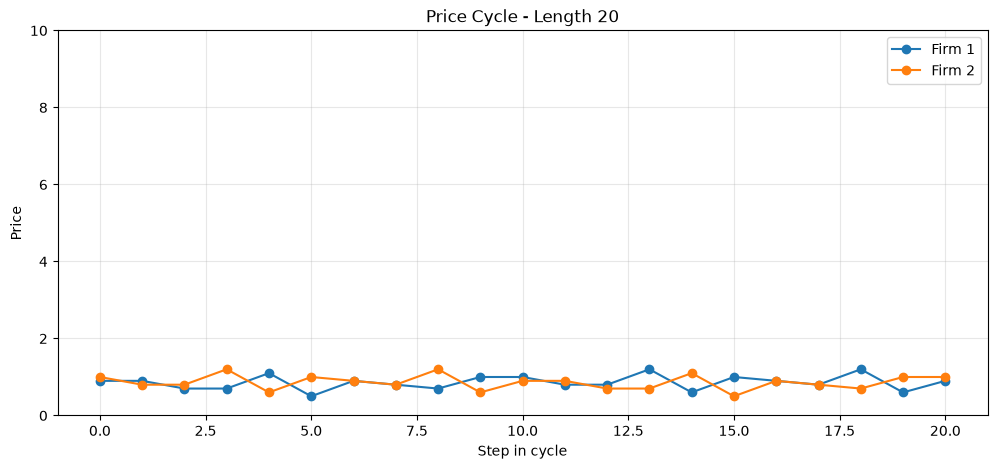

In [8]:
# Plot only the detected cycle
if 'cycle_length' in globals():

    # Extract the cycle from history
    cycle_x1 = history_x1[first_iteration:iteration + 1]
    cycle_x2 = history_x2[first_iteration:iteration + 1]

    cycle_p1 = history_p1[first_iteration:iteration + 1]
    cycle_p2 = history_p2[first_iteration:iteration + 1]

    cycle_steps = range(len(cycle_x1))


    # LOCATION CYCLE
    plt.figure(figsize=(12, 5))

    plt.plot(cycle_steps, cycle_x1, marker="o", label="Firm 1")
    plt.plot(cycle_steps, cycle_x2, marker="o", label="Firm 2")

    plt.xlabel("Step in cycle")
    plt.ylabel("Location")
    plt.title(f"Location Cycle - Length {cycle_length}")

    plt.ylim(-1, 1)
    plt.grid(alpha=0.3)
    plt.legend()

    plt.show()


    # PRICE CYCLE
    plt.figure(figsize=(12, 5))

    plt.plot(cycle_steps, cycle_p1, marker="o", label="Firm 1")
    plt.plot(cycle_steps, cycle_p2, marker="o", label="Firm 2")

    plt.xlabel("Step in cycle")
    plt.ylabel("Price")
    plt.title(f"Price Cycle - Length {cycle_length}")

    plt.ylim(0, p_max)
    plt.grid(alpha=0.3)
    plt.legend()

    plt.show()

else:
    print("No cycle was detected.")

In [9]:
profit1, profit2 = calculate_profit(
    x1, x2,
    p1, p2
)

print()
print("Final state:")

print(
    f"Firm 1: x={x1:.2f}, "
    f"p={p1:.2f}, "
    f"profit={profit1:.3f}"
)

print(
    f"Firm 2: x={x2:.2f}, "
    f"p={p2:.2f}, "
    f"profit={profit2:.3f}"
)

print()
print("Number of saved states:", len(history_x1))


Final state:
Firm 1: x=-0.30, p=0.90, profit=0.340
Firm 2: x=0.14, p=1.00, profit=0.412

Number of saved states: 352


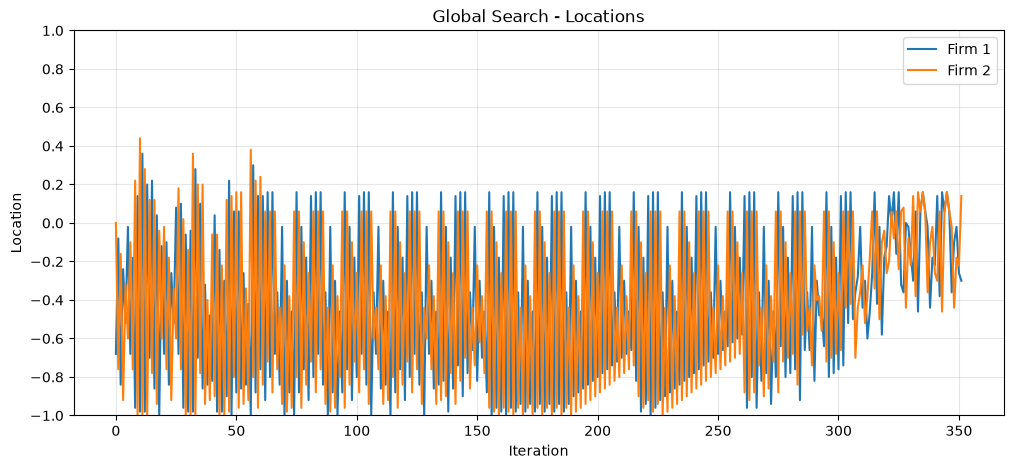

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    history_x1,
    label="Firm 1"
)

plt.plot(
    history_x2,
    label="Firm 2"
)

plt.xlabel("Iteration")
plt.ylabel("Location")

plt.title("Global Search - Locations")

plt.ylim(-1, 1)
plt.yticks(np.arange(-1, 1.1, 0.2))

plt.grid(alpha=0.3)
plt.legend()

plt.show()

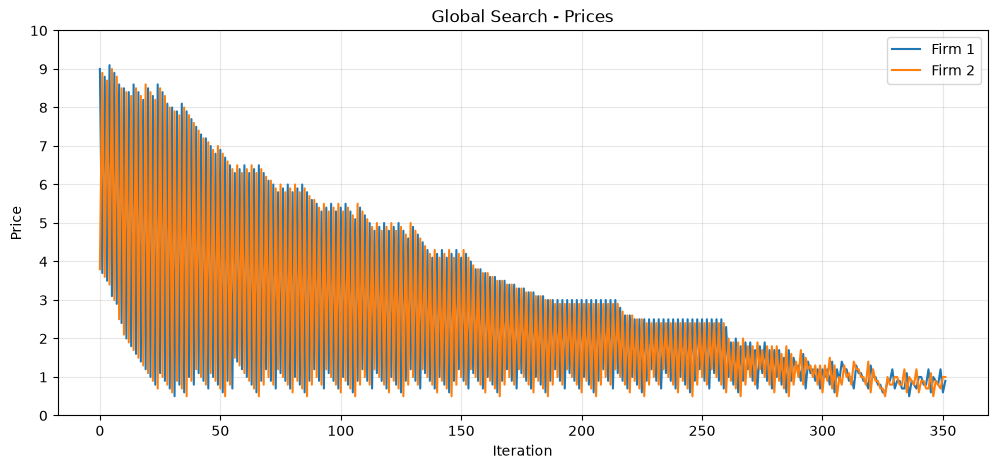

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    history_p1,
    label="Firm 1"
)

plt.plot(
    history_p2,
    label="Firm 2"
)

plt.xlabel("Iteration")
plt.ylabel("Price")

plt.title("Global Search - Prices")

plt.ylim(0, p_max)
plt.yticks(np.arange(0, p_max + 1, 1))

plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [12]:
profit_matrix = np.zeros(
    (len(road), len(prices))
)

for i, x in enumerate(road):

    for j, p in enumerate(prices):

        profit_matrix[i, j] = calculate_profit(
            x, x2,
            p, p2
        )[0]

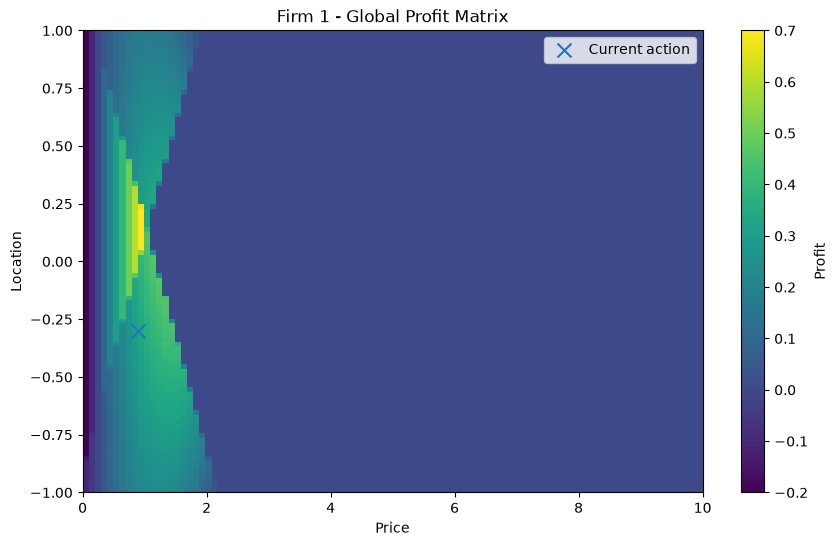

In [13]:
plt.figure(figsize=(10, 6))

plt.imshow(
    profit_matrix,
    origin="lower",
    aspect="auto",
    extent=[
        prices[0],
        prices[-1],
        road[0],
        road[-1]
    ]
)

plt.colorbar(label="Profit")

plt.xlabel("Price")
plt.ylabel("Location")

plt.title("Firm 1 - Global Profit Matrix")

plt.scatter(
    p1,
    x1,
    marker="x",
    s=100,
    label="Current action"
)

plt.legend()

plt.show()